In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/communities/communities.data"

cols = [
    "state","county","community","communityname","fold","population","householdsize",
    "racepctblack","racePctWhite","racePctAsian","racePctHisp","agePct12t21",
    "agePct12t29","agePct16t24","agePct65up","numbUrban","pctUrban","medIncome",
    "pctWWage","pctWFarmSelf","pctWInvInc","pctWSocSec","pctWPubAsst","pctWRetire",
    "medFamInc","perCapInc","whitePerCap","blackPerCap","indianPerCap","AsianPerCap",
    "OtherPerCap","HispPerCap","NumUnderPov","PctPopUnderPov","PctLess9thGrade",
    "PctNotHSGrad","PctBSorMore","PctUnemployed","PctEmploy","PctEmplManu",
    "PctEmplProfServ","PctOccupManu","PctOccupMgmtProf","MalePctDivorce","MalePctNevMarr",
    "FemalePctDiv","TotalPctDiv","PersPerFam","PctFam2Par","PctKids2Par",
    "PctYoungKids2Par","PctTeen2Par","PctWorkMomYoungKids","PctWorkMom","NumIlleg",
    "PctIlleg","NumImmig","PctImmigRecent","PctImmigRec5","PctImmigRec8",
    "PctImmigRec10","PctRecentImmig","PctRecImmig5","PctRecImmig8","PctRecImmig10",
    "PctSpeakEnglOnly","PctNotSpeakEnglWell","PctLargHouseFam","PctLargHouseOccup",
    "PersPerOccupHous","PersPerOwnOccHous","PersPerRentOccHous","PctPersOwnOccup",
    "PctPersDenseHous","PctHousLess3BR","MedNumBR","HousVacant","PctHousOccup",
    "PctHousOwnOcc","PctVacantBoarded","PctVacMore6Mos","MedYrHousBuilt",
    "PctHousNoPhone","PctWOFullPlumb","OwnOccLowQuart","OwnOccMedVal","OwnOccHiQuart",
    "RentLowQ","RentMedian","RentHighQ","MedRent","MedRentPctHousInc","MedOwnCostPctInc",
    "MedOwnCostPctIncNoMtg","NumInShelters","NumStreet","PctForeignBorn",
    "PctBornSameState","PctSameHouse85","PctSameCity85","PctSameState85","LemasSwornFT",
    "LemasSwFTPerPop","LemasSwFTFieldOps","LemasSwFTFieldPerPop","LemasTotalReq",
    "LemasTotReqPerPop","PolicReqPerOffic","PolicPerPop","RacialMatchCommPol",
    "PctPolicWhite","PctPolicBlack","PctPolicHisp","PctPolicAsian","PctPolicMinor",
    "OfficAssgnDrugUnits","NumKindsDrugsSeiz","PolicAveOTWorked","LandArea","PopDens",
    "PctUsePubTrans","PolicCars","PolicOperBudg","LemasPctPolicOnPatr",
    "LemasGangUnitDeploy","LemasPctOfficDrugUn","PolicBudgPerPop","ViolentCrimesPerPop"
]

In [3]:
df = pd.read_csv(url, header=None, names=cols, na_values="?")

audit = df.dropna(subset=["racepctblack", "ViolentCrimesPerPop"]).sample(
    n=300, random_state=42
).copy()

median = audit["racepctblack"].median()
audit["group"] = np.where(
    audit["racepctblack"] <= median, "Lower-share", "Higher-share"
)
low = audit[audit["group"] == "Lower-share"]
high = audit[audit["group"] == "Higher-share"]

mean_low = low["ViolentCrimesPerPop"].mean()
mean_high = high["ViolentCrimesPerPop"].mean()

sd_low = low["ViolentCrimesPerPop"].std()
sd_high = high["ViolentCrimesPerPop"].std()

pooled_sd = np.sqrt(
    ((len(low)-1)*sd_low**2 + (len(high)-1)*sd_high**2)
    / (len(low)+len(high)-2)
)

smd = (mean_high - mean_low) / pooled_sd

miss_low = low["PolicPerPop"].isna().mean()
miss_high = high["PolicPerPop"].isna().mean()
miss_diff = miss_high - miss_low


In [4]:
print("Sample size:", len(audit))
print("Median racepctblack:", round(median, 4))
print()
print("Lower-share mean ViolentCrimesPerPop:", round(mean_low, 4))
print("Higher-share mean ViolentCrimesPerPop:", round(mean_high, 4))
print("Standardized mean difference:", round(smd, 4))
print()
print("Lower-share PolicPerPop missing rate:", round(miss_low * 100, 2), "%")
print("Higher-share PolicPerPop missing rate:", round(miss_high * 100, 2), "%")
print("Missing-rate difference:", round(miss_diff * 100, 2), "percentage points")

Sample size: 300
Median racepctblack: 0.04

Lower-share mean ViolentCrimesPerPop: 0.1162
Higher-share mean ViolentCrimesPerPop: 0.2968
Standardized mean difference: 0.9287

Lower-share PolicPerPop missing rate: 94.84 %
Higher-share PolicPerPop missing rate: 84.14 %
Missing-rate difference: -10.7 percentage points


          Group  Mean ViolentCrimesPerPop  PolicPerPop Missing Rate
0   Lower-share                    0.1162                    0.9484
1  Higher-share                    0.2968                    0.8414


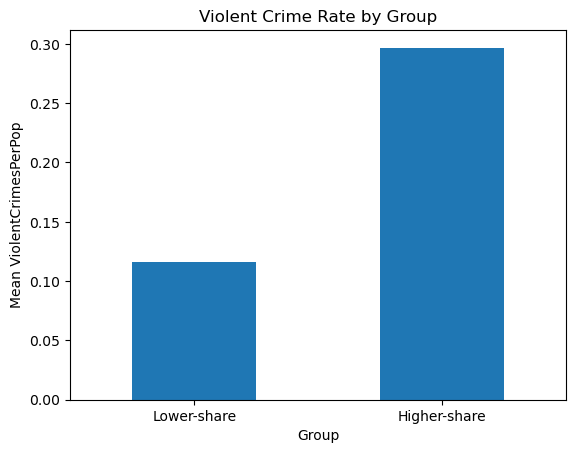

In [5]:
results = pd.DataFrame({
    "Group": ["Lower-share", "Higher-share"],
    "Mean ViolentCrimesPerPop": [mean_low, mean_high],
    "PolicPerPop Missing Rate": [miss_low, miss_high]
})

print(results.round(4))

results.plot(
    x="Group",
    y="Mean ViolentCrimesPerPop",
    kind="bar",
    legend=False
)

plt.ylabel("Mean ViolentCrimesPerPop")
plt.title("Violent Crime Rate by Group")
plt.xticks(rotation=0)
plt.show()

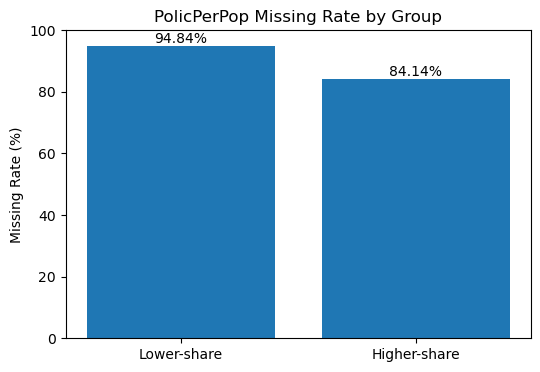

In [6]:
plt.figure(figsize=(6, 4))

groups = ["Lower-share", "Higher-share"]
missing_rates = [miss_low * 100, miss_high * 100]

plt.bar(groups, missing_rates)

plt.ylabel("Missing Rate (%)")
plt.title("PolicPerPop Missing Rate by Group")
plt.ylim(0, 100)

for i, rate in enumerate(missing_rates):
    plt.text(i, rate + 1, f"{rate:.2f}%", ha="center")

plt.show()